In [9]:
# ==========================================
# 1. IMPORT LIBRARY
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from google.colab import files
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing

from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")

# Pengaturan tampilan
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

sns.set_theme(style="whitegrid")

print("Library berhasil diimpor.")

Library berhasil diimpor.


In [11]:
# ==========================================
# 2. UPLOAD DATASET
# ==========================================

uploaded = files.upload()

nama_file = list(uploaded.keys())[0]

print("File berhasil diunggah:", nama_file)# ==========================================

Saving Harga_Pangan_Jawa_Timur_2025_12_Bulan_dengan_Estimasi.csv to Harga_Pangan_Jawa_Timur_2025_12_Bulan_dengan_Estimasi (1).csv
File berhasil diunggah: Harga_Pangan_Jawa_Timur_2025_12_Bulan_dengan_Estimasi (1).csv


In [12]:
# ==========================================
# 3. MEMBACA DATASET
# ==========================================

harga = pd.read_csv(nama_file)

print("Ukuran dataset:", harga.shape)

display(harga.head())

Ukuran dataset: (300, 11)


,Kode Provinsi,Nama Provinsi,Tahun,Urutan Bulan,Bulan,Komoditas,Harga,Harga (Rp),Status Data,Metode Estimasi,Sumber Acuan
0,35,Jawa Timur,2025,1,Januari,Bawang Merah,"Rp34,046","34,046.00",AKTUAL - SESUAI FILE SUMBER,NaN,Dataset Bapanas yang diunggah pengguna (data a...
1,35,Jawa Timur,2025,2,Februari,Bawang Merah,"Rp29,260","29,260.00",AKTUAL - SESUAI FILE SUMBER,NaN,Dataset Bapanas yang diunggah pengguna (data a...
2,35,Jawa Timur,2025,3,Maret,Bawang Merah,"Rp41,017","41,017.00",AKTUAL - SESUAI FILE SUMBER,NaN,Dataset Bapanas yang diunggah pengguna (data a...
3,35,Jawa Timur,2025,4,April,Bawang Merah,"Rp43,186","43,186.00",AKTUAL - SESUAI FILE SUMBER,NaN,Dataset Bapanas yang diunggah pengguna (data a...
4,35,Jawa Timur,2025,5,Mei,Bawang Merah,"Rp35,940","35,940.00",AKTUAL - SESUAI FILE SUMBER,NaN,Dataset Bapanas yang diunggah pengguna (data a...


In [13]:
# ==========================================
# 4. INFORMASI DATASET
# ==========================================

print("Nama kolom:")
print(harga.columns.tolist())

print("\nInformasi dataset:")
harga.info()

print("\nJumlah baris dan kolom:")
print(harga.shape)

Nama kolom:
['Kode Provinsi', 'Nama Provinsi', 'Tahun', 'Urutan Bulan', 'Bulan', 'Komoditas', 'Harga', 'Harga (Rp)', 'Status Data', 'Metode Estimasi', 'Sumber Acuan']

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Kode Provinsi    300 non-null    int64  
 1   Nama Provinsi    300 non-null    object 
 2   Tahun            300 non-null    int64  
 3   Urutan Bulan     300 non-null    int64  
 4   Bulan            300 non-null    object 
 5   Komoditas        300 non-null    object 
 6   Harga            288 non-null    object 
 7   Harga (Rp)       284 non-null    float64
 8   Status Data      300 non-null    object 
 9   Metode Estimasi  25 non-null     object 
 10  Sumber Acuan     296 non-null    object 
dtypes: float64(1), int64(3), object(7)
memory usage: 25.9+ KB

Jumlah baris dan kolom:
(300, 11)


In [14]:
# ==========================================
# 5. PEMERIKSAAN STATUS DATA
# ==========================================

print("Jumlah data berdasarkan status:")

display(
    harga["Status Data"]
    .value_counts(dropna=False)
    .reset_index()
)

print("\nMetode estimasi:")

display(
    harga["Metode Estimasi"]
    .value_counts(dropna=False)
    .reset_index()
)

Jumlah data berdasarkan status:


,Status Data,count
0,AKTUAL - SESUAI FILE SUMBER,271
1,ESTIMASI - BUKAN DATA AKTUAL BULANAN,25
2,TIDAK TERSEDIA DALAM FILE SUMBER,4



Metode estimasi:


,Metode Estimasi,count
0,NaN,275
1,Estimasi sementara: memakai harga November 202...,13
2,Estimasi proksi: rata-rata harga harian SP2KP ...,12


In [15]:
# ==========================================
# 6. PEMERIKSAAN MISSING VALUE
# ==========================================

missing = pd.DataFrame({
    "Jumlah Missing": harga.isnull().sum(),
    "Persentase Missing (%)": (
        harga.isnull().mean() * 100
    ).round(2)
})

display(missing)

,Jumlah Missing,Persentase Missing (%)
Kode Provinsi,0,0.00
Nama Provinsi,0,0.00
Tahun,0,0.00
Urutan Bulan,0,0.00
Bulan,0,0.00
Komoditas,0,0.00
Harga,12,4.00
Harga (Rp),16,5.33
Status Data,0,0.00
Metode Estimasi,275,91.67


In [16]:
# ==========================================
# 7. KONVERSI HARGA KE NUMERIK
# ==========================================

harga["Harga (Rp)"] = pd.to_numeric(
    harga["Harga (Rp)"],
    errors="coerce"
)

print("Tipe data Harga (Rp):")
print(harga["Harga (Rp)"].dtype)

display(
    harga[[
        "Komoditas",
        "Bulan",
        "Harga",
        "Harga (Rp)",
        "Status Data"
    ]].head(10)
)

Tipe data Harga (Rp):
float64


,Komoditas,Bulan,Harga,Harga (Rp),Status Data
0,Bawang Merah,Januari,"Rp34,046","34,046.00",AKTUAL - SESUAI FILE SUMBER
1,Bawang Merah,Februari,"Rp29,260","29,260.00",AKTUAL - SESUAI FILE SUMBER
2,Bawang Merah,Maret,"Rp41,017","41,017.00",AKTUAL - SESUAI FILE SUMBER
3,Bawang Merah,April,"Rp43,186","43,186.00",AKTUAL - SESUAI FILE SUMBER
4,Bawang Merah,Mei,"Rp35,940","35,940.00",AKTUAL - SESUAI FILE SUMBER
5,Bawang Merah,Juni,"Rp39,194","39,194.00",AKTUAL - SESUAI FILE SUMBER
6,Bawang Merah,Juli,"Rp41,704","41,704.00",AKTUAL - SESUAI FILE SUMBER
7,Bawang Merah,Agustus,"Rp44,313","44,313.00",AKTUAL - SESUAI FILE SUMBER
8,Bawang Merah,September,"Rp34,018","34,018.00",AKTUAL - SESUAI FILE SUMBER
9,Bawang Merah,Oktober,"Rp34,941","34,941.00",AKTUAL - SESUAI FILE SUMBER


In [17]:
# ==========================================
# 8. MEMBUAT KOLOM TANGGAL
# ==========================================

harga["Tanggal"] = pd.to_datetime(
    harga["Tahun"].astype(str)
    + "-"
    + harga["Urutan Bulan"].astype(str)
    + "-01"
)

harga = harga.sort_values(
    ["Komoditas", "Tanggal"]
).reset_index(drop=True)

display(
    harga[[
        "Tanggal",
        "Komoditas",
        "Harga (Rp)",
        "Status Data"
    ]].head(10)
)

,Tanggal,Komoditas,Harga (Rp),Status Data
0,2025-01-01,Bawang Merah,"34,046.00",AKTUAL - SESUAI FILE SUMBER
1,2025-02-01,Bawang Merah,"29,260.00",AKTUAL - SESUAI FILE SUMBER
2,2025-03-01,Bawang Merah,"41,017.00",AKTUAL - SESUAI FILE SUMBER
3,2025-04-01,Bawang Merah,"43,186.00",AKTUAL - SESUAI FILE SUMBER
4,2025-05-01,Bawang Merah,"35,940.00",AKTUAL - SESUAI FILE SUMBER
5,2025-06-01,Bawang Merah,"39,194.00",AKTUAL - SESUAI FILE SUMBER
6,2025-07-01,Bawang Merah,"41,704.00",AKTUAL - SESUAI FILE SUMBER
7,2025-08-01,Bawang Merah,"44,313.00",AKTUAL - SESUAI FILE SUMBER
8,2025-09-01,Bawang Merah,"34,018.00",AKTUAL - SESUAI FILE SUMBER
9,2025-10-01,Bawang Merah,"34,941.00",AKTUAL - SESUAI FILE SUMBER


In [18]:
# ==========================================
# 9. PEMERIKSAAN DATA AKTUAL
# ==========================================

aktual = harga[
    harga["Status Data"] == "AKTUAL - SESUAI FILE SUMBER"
].copy()

ringkasan_aktual = (
    aktual.groupby("Komoditas")
    .agg(
        Jumlah_Baris=("Komoditas", "size"),
        Harga_Tersedia=("Harga (Rp)", "count"),
        Harga_Kosong=("Harga (Rp)", lambda x: x.isna().sum())
    )
    .reset_index()
)

display(ringkasan_aktual)

,Komoditas,Jumlah_Baris,Harga_Tersedia,Harga_Kosong
0,Bawang Merah,11,11,0
1,Bawang Putih (Bonggol),11,11,0
2,Beras Medium,11,11,0
3,Beras Premium,11,11,0
4,Beras SPHP,11,11,0
5,Cabai Merah Besar,10,10,0
6,Cabai Merah Keriting,11,11,0
7,Cabai Rawit Merah,11,11,0
8,Daging Ayam Ras,11,11,0
9,Daging Kerbau Beku (Impor),10,4,6


In [19]:
# ==========================================
# 10. PEMISAHAN AKTUAL DAN ESTIMASI
# ==========================================

data_aktual = harga[
    harga["Status Data"] == "AKTUAL - SESUAI FILE SUMBER"
].copy()

data_estimasi = harga[
    harga["Status Data"] == "ESTIMASI - BUKAN DATA AKTUAL BULANAN"
].copy()

data_tidak_tersedia = harga[
    harga["Status Data"] == "TIDAK TERSEDIA DALAM FILE SUMBER"
].copy()

print("Jumlah data aktual:", len(data_aktual))
print("Jumlah data estimasi:", len(data_estimasi))
print("Jumlah data tidak tersedia:", len(data_tidak_tersedia))

Jumlah data aktual: 271
Jumlah data estimasi: 25
Jumlah data tidak tersedia: 4


In [20]:
# ==========================================
# 11. PEMILIHAN KOMODITAS
# ==========================================

komoditas_pilihan = "Cabai Rawit Merah"

print("Komoditas yang dianalisis:", komoditas_pilihan)

Komoditas yang dianalisis: Cabai Rawit Merah


In [21]:
# ==========================================
# 12. MEMBENTUK DATA DERET WAKTU
# ==========================================

data_komoditas = data_aktual[
    data_aktual["Komoditas"] == komoditas_pilihan
].copy()

data_komoditas = data_komoditas.dropna(
    subset=["Harga (Rp)"]
)

data_komoditas = data_komoditas.sort_values("Tanggal")

# Menjadikan tanggal sebagai indeks
ts = data_komoditas.set_index("Tanggal")["Harga (Rp)"]

# Frekuensi bulanan
ts = ts.asfreq("MS")

print("Jumlah observasi aktual:", len(ts))
print("Periode awal:", ts.index.min())
print("Periode akhir:", ts.index.max())

display(ts.to_frame("Harga (Rp)"))

Jumlah observasi aktual: 11
Periode awal: 2025-01-01 00:00:00
Periode akhir: 2025-11-01 00:00:00


,Harga (Rp)
Tanggal,
2025-01-01,"71,199.00"
2025-02-01,"59,913.00"
2025-03-01,"83,791.00"
2025-04-01,"63,250.00"
2025-05-01,"27,748.00"
2025-06-01,"43,655.00"
2025-07-01,"52,770.00"
2025-08-01,"28,112.00"
2025-09-01,"30,092.00"


In [22]:
# ==========================================
# 13. PEMERIKSAAN KELENGKAPAN DERET WAKTU
# ==========================================

print("Jumlah missing value:", ts.isna().sum())

print("\nTanggal dengan nilai kosong:")
print(ts[ts.isna()])

if ts.isna().any():
    raise ValueError(
        "Masih terdapat missing value. "
        "Periksa komoditas atau sumber datanya sebelum pemodelan."
    )

print("\nDeret waktu siap dianalisis.")

Jumlah missing value: 0

Tanggal dengan nilai kosong:
Series([], Freq: MS, Name: Harga (Rp), dtype: float64)

Deret waktu siap dianalisis.


In [23]:
# ==========================================
# 14. STATISTIK DESKRIPTIF
# ==========================================

statistik = ts.describe()

display(statistik.to_frame(name="Nilai"))

,Nilai
count,11.00
mean,"46,945.55"
std,"20,393.65"
min,"26,453.00"
25%,"28,765.00"
50%,"43,655.00"
75%,"61,581.50"
max,"83,791.00"


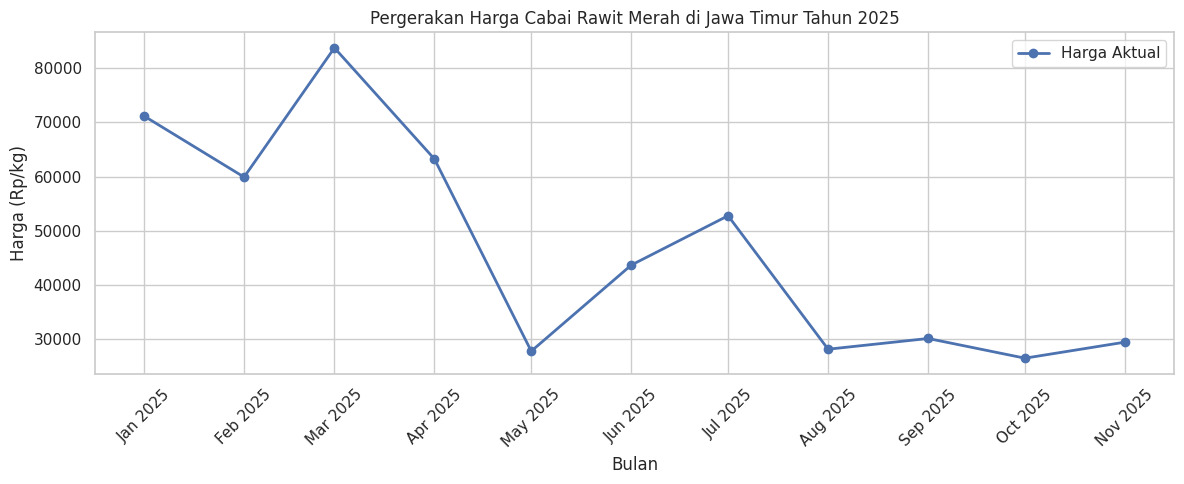

In [24]:
# ==========================================
# 15. GRAFIK DERET WAKTU AKTUAL
# ==========================================

plt.figure(figsize=(12, 5))

plt.plot(
    ts.index,
    ts.values,
    marker="o",
    linewidth=2,
    label="Harga Aktual"
)

plt.title(
    f"Pergerakan Harga {komoditas_pilihan} "
    "di Jawa Timur Tahun 2025"
)

plt.xlabel("Bulan")
plt.ylabel("Harga (Rp/kg)")
plt.xticks(ts.index, ts.index.strftime("%b %Y"), rotation=45)

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

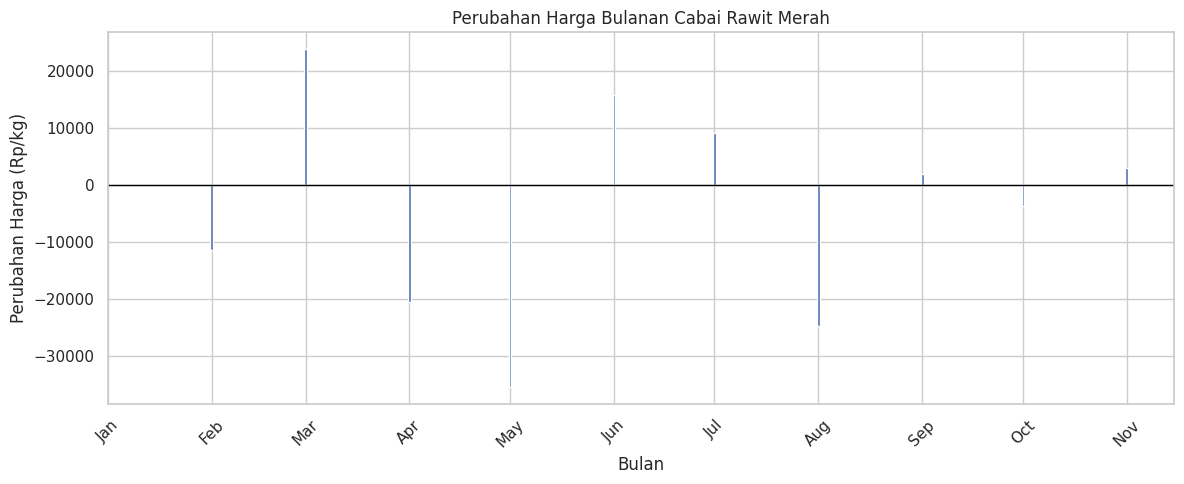

,Perubahan Harga
Tanggal,
2025-01-01,NaN
2025-02-01,"-11,286.00"
2025-03-01,"23,878.00"
2025-04-01,"-20,541.00"
2025-05-01,"-35,502.00"
2025-06-01,"15,907.00"
2025-07-01,"9,115.00"
2025-08-01,"-24,658.00"
2025-09-01,"1,980.00"


In [25]:
# ==========================================
# 16. ANALISIS PERUBAHAN HARGA
# ==========================================

perubahan = ts.diff()

plt.figure(figsize=(12, 5))

plt.bar(
    perubahan.index,
    perubahan.values
)

plt.axhline(0, color="black", linewidth=1)

plt.title(
    f"Perubahan Harga Bulanan {komoditas_pilihan}"
)

plt.xlabel("Bulan")
plt.ylabel("Perubahan Harga (Rp/kg)")
plt.xticks(perubahan.index, perubahan.index.strftime("%b"), rotation=45)

plt.tight_layout()
plt.show()

display(perubahan.to_frame("Perubahan Harga"))

In [26]:
# ==========================================
# 17. UJI STASIONERITAS ADF
# ==========================================

hasil_adf = adfuller(ts)

print("ADF Statistic:", hasil_adf[0])
print("p-value:", hasil_adf[1])
print("Critical Value:")

for key, value in hasil_adf[4].items():
    print(f"{key}: {value}")

if hasil_adf[1] < 0.05:
    print("\nKesimpulan: data stasioner berdasarkan uji ADF.")
else:
    print("\nKesimpulan: belum terdapat bukti yang cukup "
          "bahwa data stasioner berdasarkan uji ADF.")

ADF Statistic: -2.573129130332619
p-value: 0.09867907185991481
Critical Value:
1%: -4.9386902332361515
5%: -3.477582857142857
10%: -2.8438679591836733

Kesimpulan: belum terdapat bukti yang cukup bahwa data stasioner berdasarkan uji ADF.


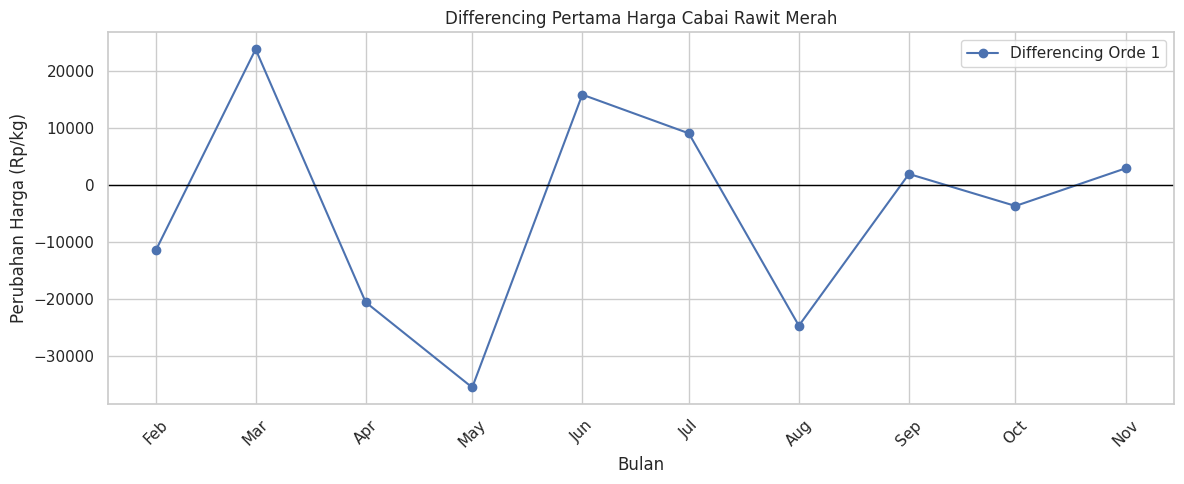

In [27]:
# ==========================================
# 18. DIFFERENCING PERTAMA
# ==========================================

ts_diff = ts.diff().dropna()

plt.figure(figsize=(12, 5))

plt.plot(
    ts_diff.index,
    ts_diff.values,
    marker="o",
    label="Differencing Orde 1"
)

plt.axhline(0, color="black", linewidth=1)

plt.title(
    f"Differencing Pertama Harga {komoditas_pilihan}"
)

plt.xlabel("Bulan")
plt.ylabel("Perubahan Harga (Rp/kg)")
plt.xticks(ts_diff.index, ts_diff.index.strftime("%b"), rotation=45)

plt.legend()
plt.tight_layout()
plt.show()

In [28]:
# ==========================================
# 19. UJI ADF SETELAH DIFFERENCING
# ==========================================

hasil_adf_diff = adfuller(ts_diff)

print("ADF Statistic:", hasil_adf_diff[0])
print("p-value:", hasil_adf_diff[1])

for key, value in hasil_adf_diff[4].items():
    print(f"Critical Value {key}: {value}")

if hasil_adf_diff[1] < 0.05:
    print("\nData hasil differencing stasioner.")
else:
    print("\nData hasil differencing belum menunjukkan "
          "stasioneritas berdasarkan uji ADF.")

ADF Statistic: -1.6177965404599854
p-value: 0.4738846748832468
Critical Value 1%: -4.9386902332361515
Critical Value 5%: -3.477582857142857
Critical Value 10%: -2.8438679591836733

Data hasil differencing belum menunjukkan stasioneritas berdasarkan uji ADF.


In [29]:
# ==========================================
# 20. TRAIN-TEST SPLIT
# ==========================================

train = ts.iloc[:8]
test = ts.iloc[8:]

print("Data latih:")
print(train)

print("\nData uji:")
print(test)

print("\nJumlah data latih:", len(train))
print("Jumlah data uji:", len(test))

Data latih:
Tanggal
2025-01-01   71,199.00
2025-02-01   59,913.00
2025-03-01   83,791.00
2025-04-01   63,250.00
2025-05-01   27,748.00
2025-06-01   43,655.00
2025-07-01   52,770.00
2025-08-01   28,112.00
Freq: MS, Name: Harga (Rp), dtype: float64

Data uji:
Tanggal
2025-09-01   30,092.00
2025-10-01   26,453.00
2025-11-01   29,418.00
Freq: MS, Name: Harga (Rp), dtype: float64

Jumlah data latih: 8
Jumlah data uji: 3


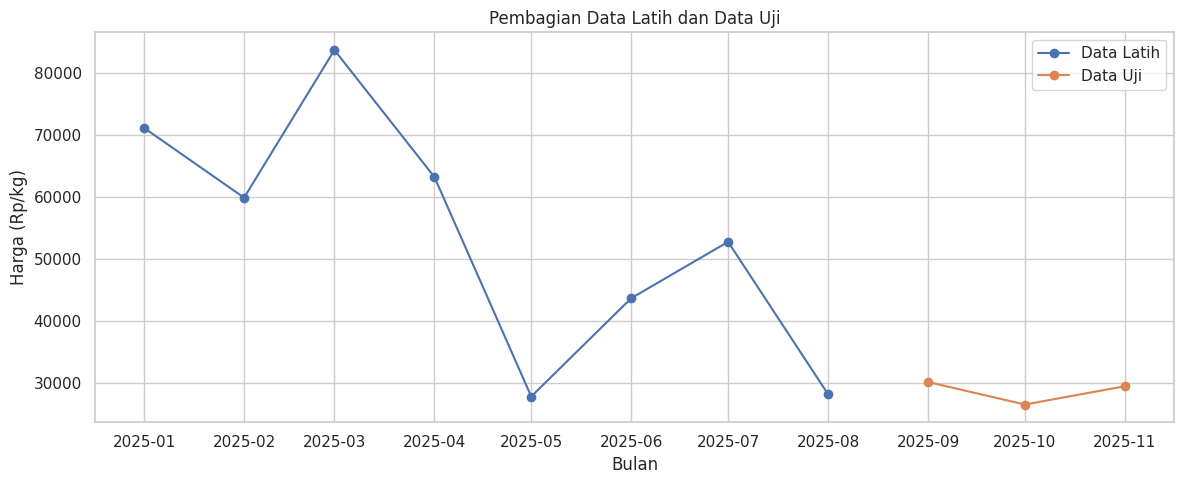

In [30]:
# ==========================================
# 21. VISUALISASI TRAIN DAN TEST
# ==========================================

plt.figure(figsize=(12, 5))

plt.plot(
    train.index,
    train.values,
    marker="o",
    label="Data Latih"
)

plt.plot(
    test.index,
    test.values,
    marker="o",
    label="Data Uji"
)

plt.title("Pembagian Data Latih dan Data Uji")

plt.xlabel("Bulan")
plt.ylabel("Harga (Rp/kg)")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Pemodelan ARIMA

In [31]:
# ==========================================
# 22. PENCARIAN ORDE ARIMA BERDASARKAN AIC
# ==========================================

hasil_arima = []

for p in range(3):
    for d in range(2):
        for q in range(3):

            try:
                model = ARIMA(
                    train,
                    order=(p, d, q)
                )

                fit = model.fit()

                hasil_arima.append({
                    "Order": (p, d, q),
                    "AIC": fit.aic,
                    "BIC": fit.bic
                })

            except Exception as e:
                print(
                    f"ARIMA({p},{d},{q}) gagal:",
                    str(e)
                )

tabel_arima = pd.DataFrame(hasil_arima)

tabel_arima = tabel_arima.sort_values(
    "AIC"
).reset_index(drop=True)

display(tabel_arima)

,Order,AIC,BIC
0,"(0, 1, 0)",161.78,161.73
1,"(0, 1, 1)",163.06,162.95
2,"(1, 1, 0)",163.17,163.06
3,"(1, 1, 1)",164.14,163.98
4,"(0, 1, 2)",164.89,164.73
5,"(2, 1, 0)",165.88,165.72
6,"(1, 1, 2)",166.29,166.08
7,"(2, 1, 1)",167.10,166.88
8,"(2, 1, 2)",168.27,168.00
9,"(0, 0, 0)",184.01,184.17


In [32]:
# ==========================================
# 23. MODEL ARIMA TERBAIK BERDASARKAN AIC
# ==========================================

if tabel_arima.empty:
    raise ValueError("Tidak ada kandidat ARIMA yang berhasil.")

order_terbaik = tabel_arima.iloc[0]["Order"]

print("Orde ARIMA terpilih:", order_terbaik)

model_arima = ARIMA(
    train,
    order=order_terbaik
)

fit_arima = model_arima.fit()

print(fit_arima.summary())

Orde ARIMA terpilih: (0, 1, 0)
                               SARIMAX Results                                
Dep. Variable:             Harga (Rp)   No. Observations:                    8
Model:                 ARIMA(0, 1, 0)   Log Likelihood                 -79.890
Date:                Tue, 24 Nov 2026   AIC                            161.780
Time:                        03:51:14   BIC                            161.726
Sample:                    01-01-2025   HQIC                           161.112
                         - 08-01-2025                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
sigma2      4.155e+08   3.46e+08      1.200      0.230   -2.63e+08    1.09e+09
Ljung-Box (L1) (Q):                   0.64   Jarque-Bera (JB):                 0.67
Prob(Q):        

In [33]:
# ==========================================
# 24. FORECAST ARIMA
# ==========================================

prediksi_arima = fit_arima.forecast(
    steps=len(test)
)

prediksi_arima.index = test.index

print("Hasil prediksi ARIMA:")
display(prediksi_arima.to_frame("Prediksi ARIMA"))

Hasil prediksi ARIMA:


,Prediksi ARIMA
Tanggal,
2025-09-01,"28,112.00"
2025-10-01,"28,112.00"
2025-11-01,"28,112.00"


# Pemodelan Exponential Smoothing

In [34]:
# ==========================================
# 25. PEMILIHAN MODEL EXPONENTIAL SMOOTHING
# ==========================================

hasil_ets = []

kandidat_ets = [
    {"trend": None, "damped_trend": False},
    {"trend": "add", "damped_trend": False},
    {"trend": "add", "damped_trend": True}
]

for konfigurasi in kandidat_ets:

    try:
        model = ExponentialSmoothing(
            train,
            trend=konfigurasi["trend"],
            damped_trend=konfigurasi["damped_trend"],
            seasonal=None,
            initialization_method="estimated"
        )

        fit = model.fit(optimized=True)

        hasil_ets.append({
            "Trend": konfigurasi["trend"],
            "Damped Trend": konfigurasi["damped_trend"],
            "AIC": fit.aic,
            "BIC": fit.bic,
            "Model": fit
        })

    except Exception as e:
        print("Kandidat ETS gagal:", konfigurasi, str(e))

if len(hasil_ets) == 0:
    raise ValueError("Tidak ada model ETS yang berhasil.")

tabel_ets = pd.DataFrame([
    {
        "Trend": x["Trend"],
        "Damped Trend": x["Damped Trend"],
        "AIC": x["AIC"],
        "BIC": x["BIC"]
    }
    for x in hasil_ets
])

display(tabel_ets.sort_values("AIC"))

,Trend,Damped Trend,AIC,BIC
1,add,False,159.91,160.23
0,None,False,161.35,161.51
2,add,True,161.92,162.31


In [35]:
# ==========================================
# 26. MODEL ETS TERBAIK BERDASARKAN AIC
# ==========================================

hasil_ets_terbaik = min(
    hasil_ets,
    key=lambda x: x["AIC"]
)

fit_ets = hasil_ets_terbaik["Model"]

print("Trend:", hasil_ets_terbaik["Trend"])
print("Damped Trend:", hasil_ets_terbaik["Damped Trend"])
print("AIC:", hasil_ets_terbaik["AIC"])

Trend: add
Damped Trend: False
AIC: 159.91014584459475


In [36]:
# ==========================================
# 27. FORECAST EXPONENTIAL SMOOTHING
# ==========================================

prediksi_ets = fit_ets.forecast(
    len(test)
)

prediksi_ets.index = test.index

print("Hasil prediksi Exponential Smoothing:")
display(prediksi_ets.to_frame("Prediksi ETS"))

Hasil prediksi Exponential Smoothing:


,Prediksi ETS
Tanggal,
2025-09-01,"31,823.51"
2025-10-01,"27,259.90"
2025-11-01,"22,696.30"


In [37]:
# ==========================================
# 28. FUNGSI EVALUASI
# ==========================================

def evaluasi_model(aktual, prediksi, train):

    mae = mean_absolute_error(
        aktual,
        prediksi
    )

    rmse = np.sqrt(
        mean_squared_error(aktual, prediksi)
    )

    # Skala MASE menggunakan kesalahan naive
    # satu langkah pada data latih
    skala_naive = np.mean(
        np.abs(np.diff(train))
    )

    if skala_naive == 0:
        mase = np.nan
    else:
        mase = mae / skala_naive

    return mae, rmse, mase

In [38]:
# ==========================================
# 29. PERBANDINGAN HASIL EVALUASI
# ==========================================

mae_arima, rmse_arima, mase_arima = evaluasi_model(
    test,
    prediksi_arima,
    train
)

mae_ets, rmse_ets, mase_ets = evaluasi_model(
    test,
    prediksi_ets,
    train
)

hasil_evaluasi = pd.DataFrame({
    "Model": [
        "ARIMA",
        "Exponential Smoothing"
    ],
    "MAE": [
        mae_arima,
        mae_ets
    ],
    "RMSE": [
        rmse_arima,
        rmse_ets
    ],
    "MASE": [
        mase_arima,
        mase_ets
    ]
})

display(hasil_evaluasi)

,Model,MAE,RMSE,MASE
0,ARIMA,"1,648.33","1,671.16",0.08
1,Exponential Smoothing,"3,086.70","4,034.45",0.15


In [39]:
# ==========================================
# 30. BASELINE NAIVE
# ==========================================

prediksi_naive = pd.Series(
    train.iloc[-1],
    index=test.index
)

mae_naive, rmse_naive, mase_naive = evaluasi_model(
    test,
    prediksi_naive,
    train
)

hasil_evaluasi = pd.concat([
    hasil_evaluasi,
    pd.DataFrame({
        "Model": ["Naive"],
        "MAE": [mae_naive],
        "RMSE": [rmse_naive],
        "MASE": [mase_naive]
    })
], ignore_index=True)

display(hasil_evaluasi)

,Model,MAE,RMSE,MASE
0,ARIMA,"1,648.33","1,671.16",0.08
1,Exponential Smoothing,"3,086.70","4,034.45",0.15
2,Naive,"1,648.33","1,671.16",0.08


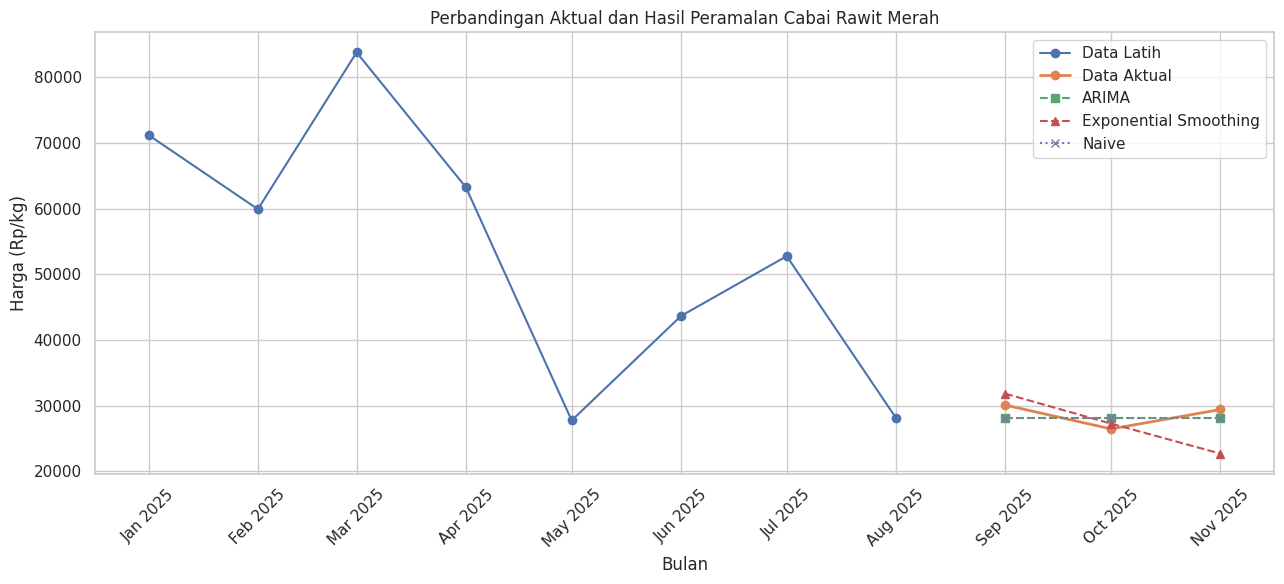

In [40]:
# ==========================================
# 31. GRAFIK PERBANDINGAN PERAMALAN
# ==========================================

plt.figure(figsize=(13, 6))

plt.plot(
    train.index,
    train.values,
    marker="o",
    label="Data Latih"
)

plt.plot(
    test.index,
    test.values,
    marker="o",
    linewidth=2,
    label="Data Aktual"
)

plt.plot(
    prediksi_arima.index,
    prediksi_arima.values,
    marker="s",
    linestyle="--",
    label="ARIMA"
)

plt.plot(
    prediksi_ets.index,
    prediksi_ets.values,
    marker="^",
    linestyle="--",
    label="Exponential Smoothing"
)

plt.plot(
    prediksi_naive.index,
    prediksi_naive.values,
    marker="x",
    linestyle=":",
    label="Naive"
)

plt.title(
    f"Perbandingan Aktual dan Hasil Peramalan "
    f"{komoditas_pilihan}"
)

plt.xlabel("Bulan")
plt.ylabel("Harga (Rp/kg)")

plt.legend()
plt.grid(True)
plt.xticks(ts.index, ts.index.strftime("%b %Y"), rotation=45)

plt.tight_layout()
plt.show()

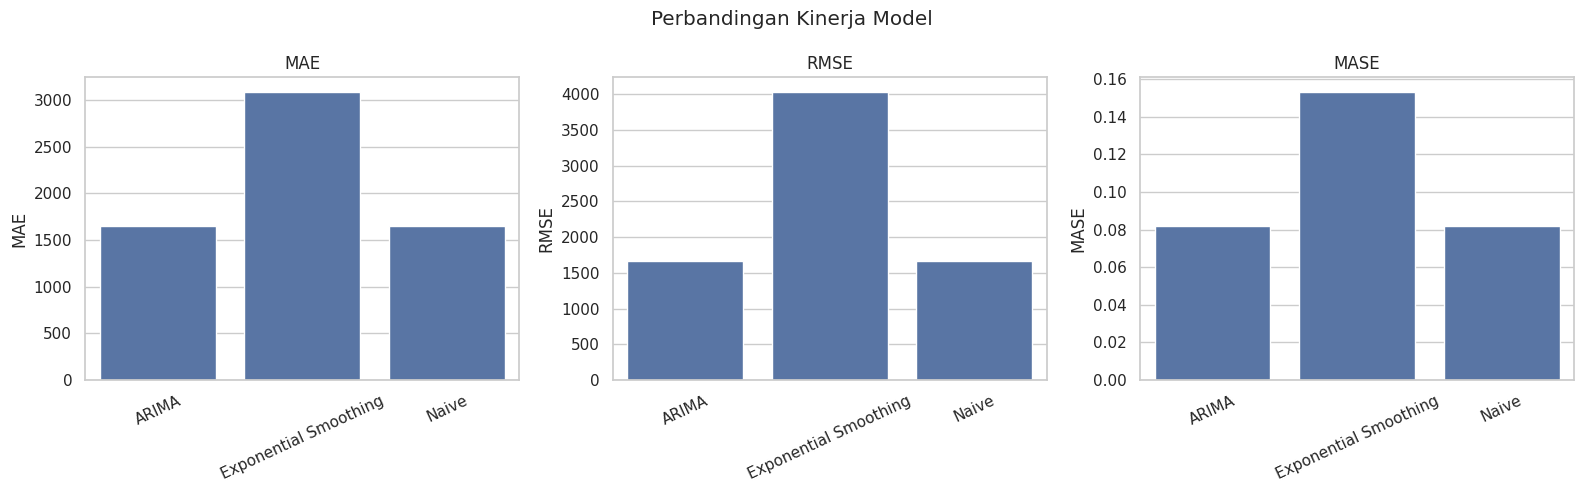

In [41]:
# ==========================================
# 32. VISUALISASI METRIK EVALUASI
# ==========================================

metrik = ["MAE", "RMSE", "MASE"]

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5)
)

for ax, kolom in zip(axes, metrik):

    sns.barplot(
        data=hasil_evaluasi,
        x="Model",
        y=kolom,
        ax=ax
    )

    ax.set_title(kolom)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=25)

plt.suptitle("Perbandingan Kinerja Model")

plt.tight_layout()
plt.show()

In [42]:
# ==========================================
# 33. MENENTUKAN MODEL TERBAIK
# ==========================================

hasil_model = hasil_evaluasi[
    hasil_evaluasi["Model"].isin([
        "ARIMA",
        "Exponential Smoothing"
    ])
]

model_terbaik = hasil_model.loc[
    hasil_model["MAE"].idxmin(),
    "Model"
]

print("Model dengan MAE terkecil:", model_terbaik)

display(
    hasil_model.sort_values("MAE")
)

Model dengan MAE terkecil: ARIMA


,Model,MAE,RMSE,MASE
0,ARIMA,"1,648.33","1,671.16",0.08
1,Exponential Smoothing,"3,086.70","4,034.45",0.15


In [43]:
# ==========================================
# 34. TABEL AKTUAL DAN PREDIKSI
# ==========================================

tabel_prediksi = pd.DataFrame({
    "Aktual": test,
    "ARIMA": prediksi_arima,
    "Exponential Smoothing": prediksi_ets,
    "Naive": prediksi_naive
})

tabel_prediksi["Error ARIMA"] = (
    tabel_prediksi["Aktual"] - tabel_prediksi["ARIMA"]
)

tabel_prediksi["Error ETS"] = (
    tabel_prediksi["Aktual"] -
    tabel_prediksi["Exponential Smoothing"]
)

display(tabel_prediksi)

,Aktual,ARIMA,Exponential Smoothing,Naive,Error ARIMA,Error ETS
Tanggal,,,,,,
2025-09-01,"30,092.00","28,112.00","31,823.51","28,112.00","1,980.00","-1,731.51"
2025-10-01,"26,453.00","28,112.00","27,259.90","28,112.00","-1,659.00",-806.90
2025-11-01,"29,418.00","28,112.00","22,696.30","28,112.00","1,306.00","6,721.70"


In [44]:
# ==========================================
# 35. RINGKASAN EKSPERIMEN
# ==========================================

print("=" * 55)
print("RINGKASAN EKSPERIMEN ANALISIS DERET WAKTU")
print("=" * 55)

print("Komoditas:", komoditas_pilihan)
print("Periode data aktual:", ts.index.min(), "-", ts.index.max())
print("Jumlah observasi:", len(ts))

print("\nPembagian data:")
print("Data latih:", len(train), "observasi")
print("Data uji:", len(test), "observasi")

print("\nModel ARIMA:")
print("Orde:", order_terbaik)

print("\nModel Exponential Smoothing:")
print("Trend:", hasil_ets_terbaik["Trend"])
print("Damped:", hasil_ets_terbaik["Damped Trend"])

print("\nModel dengan MAE terkecil:", model_terbaik)

print("\nTabel evaluasi:")
display(hasil_evaluasi)

print("=" * 55)

RINGKASAN EKSPERIMEN ANALISIS DERET WAKTU
Komoditas: Cabai Rawit Merah
Periode data aktual: 2025-01-01 00:00:00 - 2025-11-01 00:00:00
Jumlah observasi: 11

Pembagian data:
Data latih: 8 observasi
Data uji: 3 observasi

Model ARIMA:
Orde: (0, 1, 0)

Model Exponential Smoothing:
Trend: add
Damped: False

Model dengan MAE terkecil: ARIMA

Tabel evaluasi:


,Model,MAE,RMSE,MASE
0,ARIMA,"1,648.33","1,671.16",0.08
1,Exponential Smoothing,"3,086.70","4,034.45",0.15
2,Naive,"1,648.33","1,671.16",0.08


In [45]:
# ==========================================
# 36. EKSPOR HASIL ANALISIS
# ==========================================

nama_output = "Hasil_Analisis_Deret_Waktu.xlsx"

with pd.ExcelWriter(nama_output) as writer:

    harga.to_excel(
        writer,
        sheet_name="Data Awal",
        index=False
    )

    data_aktual.to_excel(
        writer,
        sheet_name="Data Aktual",
        index=False
    )

    ts.to_frame("Harga Aktual").to_excel(
        writer,
        sheet_name="Deret Waktu"
    )

    tabel_arima.to_excel(
        writer,
        sheet_name="Kandidat ARIMA",
        index=False
    )

    tabel_ets.drop(
        columns=[],
        errors="ignore"
    ).to_excel(
        writer,
        sheet_name="Kandidat ETS",
        index=False
    )

    tabel_prediksi.to_excel(
        writer,
        sheet_name="Prediksi"
    )

    hasil_evaluasi.to_excel(
        writer,
        sheet_name="Evaluasi",
        index=False
    )

print("File berhasil disimpan:", nama_output)

files.download(nama_output)

File berhasil disimpan: Hasil_Analisis_Deret_Waktu.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>